## Exercise 1: Knapsack Problem

We model the knapsack as a **multidimensional 0/1 knapsack problem** with two constraints
(weight ≤ 250, volume ≤ 250). Following the lecture (INNGA_06), we define the
**Lagrange penalty-based fitness function**:

$$f(x) = \mathbf{p}^T\mathbf{x} + \underbrace{(\sum p)\cdot((L_w - \mathbf{w}^T\mathbf{x}) < 0)
\cdot(L_w - \mathbf{w}^T\mathbf{x})}_{\text{weight penalty}}
+ \underbrace{(\sum p)\cdot((L_v - \mathbf{v}^T\mathbf{x}) < 0)
\cdot(L_v - \mathbf{v}^T\mathbf{x})}_{\text{volume penalty}}$$

The penalty constant is set to $pen = \sum p = 578$, ensuring that any infeasible
solution (constraint violated → slack < 0) is always worse than any feasible one.

In [8]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Genome: binary vector x ∈ {0,1}^19 (1 = item selected)

values  = np.array([48, 30, 42, 36, 22, 43, 18, 24, 36, 29,
                    30, 25, 19, 41, 34, 32, 27, 24, 18])
weights = np.array([10, 30, 12, 22, 12, 20,  9,  9, 18, 20,
                    25, 18,  7, 16, 24, 21, 21, 32,  9])
volumes = np.array([15, 20, 18, 20,  5, 12,  7,  7, 24, 30,
                    25, 20,  5, 25, 19, 24, 19, 14, 30])

W_CAP = 250   # weight capacity
V_CAP = 250   # volume capacity
N     = len(values)

PEN = values.sum()

def fitness(x):
    """
    Lagrange / penalty-based fitness function (from lecture INNGA_06):
      f(x) = p^T x
              + pen * ((W_cap - w^T x) < 0) * (W_cap - w^T x)
              + pen * ((V_cap - v^T x) < 0) * (V_cap - v^T x)
    Maximise this value.
    """
    val    = values  @ x
    s_w    = W_CAP - weights @ x   # slack weight  (< 0 → violated)
    s_v    = V_CAP - volumes @ x   # slack volume  (< 0 → violated)
    pen_w  = PEN * (s_w < 0) * s_w
    pen_v  = PEN * (s_v < 0) * s_v
    return val + pen_w + pen_v

print(f"Number of items : {N}")
print(f"Total value     : {values.sum()}  |  Max weight: {weights.sum()}  |  Max volume: {volumes.sum()}")
print(f"Penalty constant: {PEN}")

Number of items : 19
Total value     : 578  |  Max weight: 335  |  Max volume: 339
Penalty constant: 578


### Genetic Operators

We implement the three standard SGA operators from the lecture:

- **Selection**: Stochastic Universal Sampling (SUS) — zero bias, O(n) complexity (INNGA_07).
  Fitness is shifted to be strictly positive before sampling.
- **Crossover**: One-point crossover with rate 0.7 — splits two parent genomes at a random
  point and swaps the tails to produce two offspring.
- **Mutation**: Bit-flip mutation with rate $1/n$ per bit — each bit is independently
  flipped, expecting roughly one flip per genome per generation.

In [9]:

# Selection: proportional to fitness (roulette wheel), with shift to keep positive
# Crossover: one-point crossover
# Mutation : bit-flip with rate bitmutrate

def sus_selection(population, fitnesses, n_select):
    """
    Stochastic Universal Sampling (SUS) — O(n), zero bias (INNGA_07).
    Shifts fitness so all values are > 0 before sampling.
    """
    fit = np.array(fitnesses, dtype=float)
    fit -= fit.min() - 1e-6          # shift: all values > 0
    total = fit.sum()
    ptr   = random.uniform(0, 1)
    exp_num = fit / fit.mean()
    selected = []
    cum = 0.0
    for j, e in enumerate(exp_num):
        cum += e
        while cum > ptr:
            selected.append(j)
            ptr += 1
    # SUS may return slightly more/less than n_select — trim / pad
    while len(selected) < n_select:
        selected.append(random.randrange(len(population)))
    return [population[i] for i in selected[:n_select]]

def one_point_crossover(p1, p2, crossrate=0.7):
    """One-point crossover, produces two offspring."""
    if random.random() < crossrate:
        pt = random.randint(1, N - 1)
        c1 = np.concatenate([p1[:pt], p2[pt:]])
        c2 = np.concatenate([p2[:pt], p1[pt:]])
        return c1, c2
    return p1.copy(), p2.copy()

def bit_mutation(x, bitmutrate=0.01):
    """Flip each bit independently with probability bitmutrate."""
    child = x.copy()
    for i in range(N):
        if random.random() < bitmutrate:
            child[i] = 1 - child[i]
    return child

print("Genetic operators defined: SUS selection, one-point crossover, bit mutation.")

Genetic operators defined: SUS selection, one-point crossover, bit mutation.


### SGA Main Loop

The main loop follows the standard Simple Genetic Algorithm structure from the lecture:

1. Evaluate fitness of all individuals
2. Select parents via SUS
3. Apply crossover + mutation to produce the next generation
4. Keep the best individual unchanged 

We run for **100 generations** with a population size of **200**.
Note that feasibility of the final solution must be checked explicitly afterwards,
since the GA works on the unconstrained penalized fitness internally.

In [22]:

POPSIZE     = 200
GENERATIONS = 100
CROSSRATE   = 0.7
BITMUTRATE  = 1 / N      # ≈ 1 bit flip expected per genome
SEED        = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Initialise random binary population ──
population = [np.random.randint(0, 2, N) for _ in range(POPSIZE)]

# ── Statistics tracking ──
stats = {"min": [], "max": [], "mean": [], "median": []}

best_solution  = None
best_fitness   = -np.inf

for gen in range(GENERATIONS):
    fitnesses = [fitness(ind) for ind in population]

    # Track best (elitism: keep best ever found)
    gen_best_idx = int(np.argmax(fitnesses))
    if fitnesses[gen_best_idx] > best_fitness:
        best_fitness  = fitnesses[gen_best_idx]
        best_solution = population[gen_best_idx].copy()

    stats["min"].append(np.min(fitnesses))
    stats["max"].append(np.max(fitnesses))
    stats["mean"].append(np.mean(fitnesses))
    stats["median"].append(np.median(fitnesses))

    # ── Reproduction via SUS ──
    new_pop = [best_solution.copy()]   # elitism: keep best

    parents = sus_selection(population, fitnesses, POPSIZE)
    random.shuffle(parents)

    i = 0
    while len(new_pop) < POPSIZE:
        p1 = parents[i % POPSIZE]
        p2 = parents[(i + 1) % POPSIZE]
        c1, c2 = one_point_crossover(p1, p2, CROSSRATE)
        c1 = bit_mutation(c1, BITMUTRATE)
        c2 = bit_mutation(c2, BITMUTRATE)
        new_pop.extend([c1, c2])
        i += 2

    population = new_pop[:POPSIZE]

print(f"GA finished after {GENERATIONS} generations.")
print(f"Best raw fitness (penalty included): {best_fitness:.2f}")

GA finished after 100 generations.
Best raw fitness (penalty included): 477.00


### Results & Interpretation

The GA found a **feasible solution** with a total value of **477** out of a theoretical
maximum of 578 (all items), selecting **15 out of 19 items**.

Both capacity constraints are satisfied:
- Weight: 249 / 250 (slack: 1) → almost fully utilized
- Volume: 240 / 250 (slack: 10) → well within limit

The **weight constraint is the binding constraint** — with only 1 unit of slack,
no additional item could be added without violating it.

The 4 items **not** selected are items 10, 11, 18, and 19. This makes intuitive sense:
- **Item 18** has the worst value-to-weight ratio (value 24, weight 32)
- **Item 19** has the lowest value of all items (18)
- **Item 10** consumes a lot of volume (30) for relatively little value (29)
- **Item 11** (value 30, weight 25) likely couldn't fit given the tight weight budget

Note that since the GA is a heuristic, **optimality is not guaranteed**. To verify
the solution quality, one could compare against an exact solver

In [23]:
x = best_solution
selected_idx = np.where(x == 1)[0]

total_value  = values[selected_idx].sum()
total_weight = weights[selected_idx].sum()
total_volume = volumes[selected_idx].sum()

feasible = (total_weight <= W_CAP) and (total_volume <= V_CAP)

print("=" * 55)
print("  KNAPSACK SOLUTION (Genetic Algorithm, SGA)")
print("=" * 55)
print(f"  Selected item indices (1-based): {list(selected_idx + 1)}")
print(f"  Total value  : {total_value}")
print(f"  Total weight : {total_weight}  / {W_CAP}  (slack: {W_CAP - total_weight})")
print(f"  Total volume : {total_volume}  / {V_CAP}  (slack: {V_CAP - total_volume})")
print(f"  Feasible     : {feasible}")
print("=" * 55)

print("\nItem details:")
print(f"{'Idx':>4}  {'Value':>6}  {'Weight':>7}  {'Volume':>7}")
for i in selected_idx:
    print(f"  {i+1:>2}    {values[i]:>5}    {weights[i]:>5}    {volumes[i]:>5}")

  KNAPSACK SOLUTION (Genetic Algorithm, SGA)
  Selected item indices (1-based): [1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14, 15, 16, 17]
  Total value  : 477
  Total weight : 249  / 250  (slack: 1)
  Total volume : 240  / 250  (slack: 10)
  Feasible     : True

Item details:
 Idx   Value   Weight   Volume
   1       48       10       15
   2       30       30       20
   3       42       12       18
   4       36       22       20
   5       22       12        5
   6       43       20       12
   7       18        9        7
   8       24        9        7
   9       36       18       24
  12       25       18       20
  13       19        7        5
  14       41       16       25
  15       34       24       19
  16       32       21       24
  17       27       21       19


### Fitness Statistics over Generations

We plot the min, mean, median and max fitness across all generations —
analogous to the population fitness plot shown in the lecture.
This gives a visual impression of how fast the population converges and whether
the GA is still exploring or has already settled on a solution.

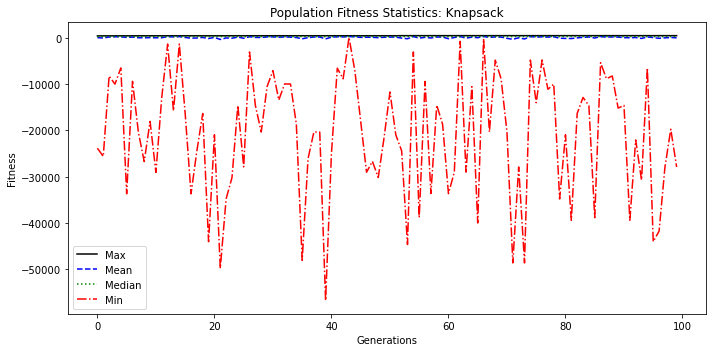

In [24]:
# ── Plot fitness statistics over generations (analog INNGA_06 slide) ───────────
gens = range(GENERATIONS)

plt.figure(figsize=(10, 5))
plt.plot(gens, stats["max"],    label="Max",    color="black",  linestyle="-")
plt.plot(gens, stats["mean"],   label="Mean",   color="blue",   linestyle="--")
plt.plot(gens, stats["median"], label="Median", color="green",  linestyle=":")
plt.plot(gens, stats["min"],    label="Min",    color="red",    linestyle="-.")
plt.xlabel("Generations")
plt.ylabel("Fitness")
plt.title("Population Fitness Statistics: Knapsack")
plt.legend()
plt.tight_layout()
plt.show()

### Brute Force Comparison

The brute force search confirms that the GA found the **optimal value of 477**.
Interestingly, the brute force picks a slightly different combination: instead of
**item 2** (value 30, weight 30), it selects **item 11** (value 30, weight 25) —
both solutions are feasible and yield the exact same total value, so there are
**multiple optimal solutions** to this problem.

This is only feasible because we have just **19 items** → 2¹⁹ = 524,288 combinations
to check. With **100 items**, brute force would require checking 2¹⁰⁰ ≈ 10³⁰
combinations — completely intractable even for modern hardware. This is exactly
why heuristics like the **Genetic Algorithm** are needed for real-world knapsack problems.

In [25]:
# ── Brute Force Optimal Solution ───────────────────────────────────────────────
from itertools import product

best_value  = 0
best_combo  = None

for x in product([0, 1], repeat=N):
    x = np.array(x)
    total_w = weights @ x
    total_v = volumes @ x
    total_val = values @ x
    
    if total_w <= W_CAP and total_v <= V_CAP:
        if total_val > best_value:
            best_value = total_val
            best_combo = x.copy()

selected_bf  = np.where(best_combo == 1)[0]
print("=" * 55)
print("  BRUTE FORCE OPTIMAL SOLUTION")
print("=" * 55)
print(f"  Selected items (1-based): {list(selected_bf + 1)}")
print(f"  Total value  : {best_value}")
print(f"  Total weight : {weights @ best_combo} / {W_CAP}  (slack: {W_CAP - weights @ best_combo})")
print(f"  Total volume : {volumes @ best_combo} / {V_CAP}  (slack: {V_CAP - volumes @ best_combo})")
print("=" * 55)
print(f"\n  GA solution  : 477")
print(f"  Optimal      : {best_value}")
print(f"  Gap          : {best_value - 477}")

  BRUTE FORCE OPTIMAL SOLUTION
  Selected items (1-based): [1, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17]
  Total value  : 477
  Total weight : 244 / 250  (slack: 6)
  Total volume : 245 / 250  (slack: 5)

  GA solution  : 477
  Optimal      : 477
  Gap          : 0
